# Adidas US Sales | Business Performance Analysis
### Independent data analytics case study · 2020–2021

**Business question:** Which commercial segments generate the most volume, modeled revenue and operating profit—and what can reasonably be inferred from this sample?

This end-to-end notebook preserves the original project's analytical themes while delivering a concise, English-language management narrative. All numbers and plots are recomputed from the source workbook. **Not an official Adidas financial statement.**

## 1. Business context and data understanding

**Scope:** Retailers, products, geography, recorded sales methods, monthly patterns, holiday windows and modeled operating economics. One record is a *sales row*, not a unique order or buyer. The workbook comes from [Kaggle — Adidas Sales Dataset](https://www.kaggle.com/datasets/heemalichaudhari/adidas-sales-dataset).

**Accounting decision:** 3,886 source revenue values are ten times the arithmetic `price_per_unit × units_sold`. Consistent with the original author's transformation, this notebook recomputes sales and profit. Resulting aggregate values are **one possible, transparent normalization**, not verified official performance.

**Source access:** Put `Adidas US Sales Datasets.xlsx` in `data/` (GitHub) or attach the corresponding Kaggle dataset (`/kaggle/input/`). Source workbook is intentionally not redistributed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4.8), "figure.dpi": 110, "font.size": 10})

search_roots = [Path.cwd(), Path.cwd().parent, Path('/kaggle/input')]
local_names = [root / 'data' / 'Adidas US Sales Datasets.xlsx' for root in search_roots]
local_names += [root / 'Adidas US Sales Datasets.xlsx' for root in search_roots]
excel_file = next((p for p in local_names if p.is_file()), None)
if excel_file is None and Path('/kaggle/input').exists():
    excel_file = next((p for p in Path('/kaggle/input').rglob('*.xlsx') if 'adidas' in p.name.lower() and 'sales' in p.name.lower()), None)
if excel_file is None:
    raise FileNotFoundError('Download Adidas US Sales Datasets.xlsx from Kaggle and place in data/, or attach the Kaggle dataset.')
print('Source workbook:', excel_file.name)

Source workbook: Adidas US Sales Datasets.xlsx


## 2. Data cleaning and the normalization audit

Convert names, dates and numeric types, drop invalid rows and complete duplicates, compare source financial columns with arithmetic totals, and implement the author's recomputation rule. Preserve zero-unit records.

In [2]:
raw = pd.read_excel(
    excel_file,
    sheet_name="ADIdata_RAW",
    header=4,
    usecols="B:N",
    dtype={"Retailer ID": "string"},
    engine="openpyxl",
)

raw.columns = (
    raw.columns.astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

EXPECTED_COLS = [
    "retailer", "retailer_id", "invoice_date", "region", "state", "city",
    "product", "price_per_unit", "units_sold", "total_sales",
    "operating_profit", "operating_margin", "sales_method",
]
missing_cols = set(EXPECTED_COLS) - set(raw.columns)
if missing_cols:
    raise ValueError(f"Expected columns missing: {sorted(missing_cols)}")

df = raw[EXPECTED_COLS].copy()
initial_rows = len(df)
print("Initial shape:", df.shape)
print("Null values per field (before cleaning):")
print(df.isna().sum().to_string())

Initial shape: (9648, 13)
Null values per field (before cleaning):
retailer            0
retailer_id         0
invoice_date        0
region              0
state               0
city                0
product             0
price_per_unit      0
units_sold          0
total_sales         0
operating_profit    0
operating_margin    0
sales_method        0


In [3]:
df = df.dropna(how="all").copy()

TEXT_COLS = ["retailer", "retailer_id", "region", "state", "city", "product", "sales_method"]
NULL_TOKENS = {"", "none", "null", "nan", "n/a", "na", "-"}

for col in TEXT_COLS:
    series = (
        df[col].astype("string")
        .str.replace("\u00a0", " ", regex=False)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )
    df[col] = series.mask(series.str.casefold().isin(NULL_TOKENS))

df["retailer_id"] = df["retailer_id"].str.replace(r"\.0$", "", regex=True)

CANONICAL_LABELS = {
    "retailer": ["Foot Locker", "West Gear", "Sports Direct", "Kohl's", "Amazon", "Walmart"],
    "region": ["West", "Northeast", "Midwest", "South", "Southeast"],
    "product": [
        "Men's Street Footwear", "Men's Athletic Footwear", "Men's Apparel",
        "Women's Street Footwear", "Women's Athletic Footwear", "Women's Apparel",
    ],
    "sales_method": ["Online", "Outlet", "In-store"],
}

for col, labels in CANONICAL_LABELS.items():
    canonical_map = {label.casefold(): label for label in labels}
    df[col] = df[col].map(
        lambda value: canonical_map.get(value.casefold(), value) if pd.notna(value) else pd.NA
    ).astype("string")

for col in ["state", "city"]:
    df[col] = df[col].str.title()

print("Text normalized; unrecognized categories are not removed automatically.")

Text normalized; unrecognized categories are not removed automatically.


In [4]:
FINANCIAL_COLS = ["price_per_unit", "units_sold", "total_sales", "operating_profit", "operating_margin"]

for col in FINANCIAL_COLS:
    cleaned = (
        df[col].astype("string")
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(cleaned, errors="coerce")

raw_date = df["invoice_date"]
numeric_date = pd.to_numeric(raw_date, errors="coerce")
is_excel_serial = numeric_date.between(20_000, 80_000)
parsed_date = pd.to_datetime(raw_date, errors="coerce")
parsed_date.loc[is_excel_serial] = pd.to_datetime(
    numeric_date.loc[is_excel_serial], unit="D", origin="1899-12-30", errors="coerce"
)
df["invoice_date"] = parsed_date.dt.normalize()

for col in ["price_per_unit", "total_sales", "operating_profit"]:
    df[col] = df[col].round(2)
df["operating_margin"] = df["operating_margin"].round(4)

print(df.dtypes.to_string())

retailer            string[python]
retailer_id         string[python]
invoice_date        datetime64[ns]
region              string[python]
state               string[python]
city                string[python]
product             string[python]
price_per_unit             Float64
units_sold                   Int64
total_sales                Float64
operating_profit           Float64
operating_margin           Float64
sales_method        string[python]


In [5]:
MANDATORY_COLS = [
    "retailer", "retailer_id", "invoice_date", "region", "state", "city",
    "product", "price_per_unit", "units_sold", "sales_method",
]

invalid_missing = df[MANDATORY_COLS].isna().any(axis=1)
invalid_price = df["price_per_unit"].lt(0).fillna(False)
invalid_units = (
    df["units_sold"].lt(0).fillna(False)
    | df["units_sold"].mod(1).ne(0).fillna(False)
)
invalid_mask = invalid_missing | invalid_price | invalid_units
rejected = df.loc[invalid_mask].copy()

if not rejected.empty:
    rejected.to_csv(OUTPUT_DIR / "adidas_rejected_rows.csv", index=False, date_format="%Y-%m-%d")

df = df.loc[~invalid_mask].copy()
df["units_sold"] = df["units_sold"].astype("int64")

print("Rows removed for missing/invalid mandatory values:", len(rejected))
print("Valid records remaining:", len(df))
print("Zero-unit records (retained):", int(df["units_sold"].eq(0).sum()))

Rows removed for missing/invalid mandatory values: 0
Valid records remaining: 9648
Zero-unit records (retained): 4


In [6]:
duplicate_mask = df.duplicated(keep="first")
num_duplicates = int(duplicate_mask.sum())
df = df.loc[~duplicate_mask].reset_index(drop=True)
print("Exact duplicate records removed:", num_duplicates)
print("Rows after deduplication:", len(df))

Exact duplicate records removed: 0
Rows after deduplication: 9648


In [7]:
old_total_sales = df["total_sales"].copy()
recalculated_total_sales = (df["price_per_unit"] * df["units_sold"]).round(2)

diff = (old_total_sales - recalculated_total_sales).abs()
mismatch_mask = (old_total_sales.notna() & diff.gt(0.01)).fillna(False)
num_mismatch = int(mismatch_mask.sum())

tenfold_mask = (
    recalculated_total_sales.gt(0)
    & (old_total_sales / recalculated_total_sales).sub(10).abs().lt(0.000001)
).fillna(False)

print("Raw revenue cells differing from price × units:", num_mismatch)
print("Of which exactly tenfold:", int(tenfold_mask.sum()))

old_position = df.columns.get_loc("total_sales")
df = df.drop(columns="total_sales")
df.insert(old_position, "total_sales", recalculated_total_sales)

Raw revenue cells differing from price × units: 3886
Of which exactly tenfold: 3886


In [8]:
if df["operating_margin"].isna().any() or not df["operating_margin"].between(0, 1).all():
    raise ValueError("Operating Margin missing or outside [0, 1]")

old_operating_profit = df["operating_profit"].copy()
recalculated_operating_profit = (df["total_sales"] * df["operating_margin"]).round(2)

num_profit_changed = int(
    (old_operating_profit.isna() | (old_operating_profit - recalculated_operating_profit).abs().gt(0.01)).sum()
)

profit_position = df.columns.get_loc("operating_profit")
df = df.drop(columns="operating_profit")
df.insert(profit_position, "operating_profit", recalculated_operating_profit)

print("Modeled operating profit recalculated for records:", len(df))
print("Values different from source reported profit:", num_profit_changed)

Modeled operating profit recalculated for records: 9648
Values different from source reported profit: 3886


In [9]:
margin_diff = (
    df["operating_profit"] - (df["total_sales"] * df["operating_margin"]).round(2)
).abs()

print("Rows with inconsistent recomputed revenue:", int(
    (df["total_sales"] - df["price_per_unit"] * df["units_sold"]).abs().gt(0.01).sum()
))
print("Rows with inconsistent modeled profit vs margin:", int(margin_diff.gt(0.01).sum()))
print("Rows with profit greater than revenue:", int(df["operating_profit"].gt(df["total_sales"]).sum()))

Rows with inconsistent recomputed revenue: 0
Rows with inconsistent modeled profit vs margin: 0
Rows with profit greater than revenue: 0


In [10]:
assert len(df) == 9648, "Unexpected record count; recheck source workbook version"
assert np.allclose(df.total_sales.to_numpy(dtype=float), (df.price_per_unit * df.units_sold).to_numpy(dtype=float), atol=.01)
assert np.allclose(df.operating_profit.to_numpy(dtype=float), (df.total_sales * df.operating_margin).to_numpy(dtype=float), atol=.01)
print(f"Audited rows: {len(df):,} | 10× sales discrepancies: {num_mismatch:,} | rejected: {len(rejected):,} | duplicates: {num_duplicates:,}")
print(f"Raw revenue: ${old_total_sales.sum()/1e6:,.2f}M | Recomputed: ${df.total_sales.sum()/1e6:,.2f}M")

Audited rows: 9,648 | 10× sales discrepancies: 3,886 | rejected: 0 | duplicates: 0
Raw revenue: $899.90M | Recomputed: $120.17M


## 3. Exploratory features and KPIs

Create time and product classifications, then define revenue-weighted margin and unit-weighted realized price. Product gender is a label on merchandise; no customer-demographic conclusion follows.

In [11]:
MONTH_NAMES_IT = {
    1: "Gennaio", 2: "Febbraio", 3: "Marzo", 4: "Aprile",
    5: "Maggio", 6: "Giugno", 7: "Luglio", 8: "Agosto",
    9: "Settembre", 10: "Ottobre", 11: "Novembre", 12: "Dicembre",
}

df["year"] = df["invoice_date"].dt.year.astype("int64")
df["month_number"] = df["invoice_date"].dt.month.astype("int64")
df["month_name_it"] = df["month_number"].map(MONTH_NAMES_IT).astype("string")
df["year_month"] = df["invoice_date"].dt.strftime("%Y-%m").astype("string")

In [12]:
WEEKDAY_NAMES_IT = {
    0: "Lunedì", 1: "Martedì", 2: "Mercoledì", 3: "Giovedì",
    4: "Venerdì", 5: "Sabato", 6: "Domenica",
}

df["weekday_number"] = df["invoice_date"].dt.dayofweek.astype("int64")
df["weekday_name_it"] = df["weekday_number"].map(WEEKDAY_NAMES_IT).astype("string")
df["is_weekend"] = df["weekday_number"].isin([5, 6])

In [13]:
SEASON_BY_MONTH = {
    12: "Inverno", 1: "Inverno", 2: "Inverno",
    3: "Primavera", 4: "Primavera", 5: "Primavera",
    6: "Estate", 7: "Estate", 8: "Estate",
    9: "Autunno", 10: "Autunno", 11: "Autunno",
}
df["season_it"] = df["month_number"].map(SEASON_BY_MONTH).astype("string")

In [14]:
product_text = df["product"].astype("string")
product_gender_source = product_text.str.extract(r"^(Men's|Women's)\b", flags=0, expand=False)
GENDER_MAP = {"Men's": "Uomo", "Women's": "Donna"}
df["product_gender"] = (
    product_gender_source.map(GENDER_MAP).fillna("Non classificato").astype("string")
)

In [15]:
is_apparel = product_text.str.contains("Apparel", case=False, na=False, regex=False)
is_footwear = product_text.str.contains("Footwear", case=False, na=False, regex=False)

df["product_category"] = pd.Series("Non classificato", index=df.index, dtype="string")
df.loc[is_apparel, "product_category"] = "Abbigliamento"
df.loc[is_footwear & ~is_apparel, "product_category"] = "Calzature"

In [16]:
assert not df[['year','month_number','weekday_number','is_weekend','season_it','product_gender','product_category']].isna().any().any()
assert set(df.product_category) == {'Calzature','Abbigliamento'}

def group_metrics(columns, data=None):
    src = df if data is None else data
    g = src.groupby(columns, observed=True, dropna=False).agg(
        records=('units_sold','size'), units=('units_sold','sum'),
        revenue=('total_sales','sum'), profit=('operating_profit','sum'),
        observed_days=('invoice_date','nunique')).reset_index()
    g['margin_pct'] = 100*g['profit']/g['revenue'].replace(0, np.nan)
    g['realized_unit_price'] = g['revenue']/g['units'].replace(0, np.nan)
    return g

def finding(message):
    display(Markdown('**Observed result.** ' + message))

def caveat(message):
    display(Markdown('**Interpretation limit.** ' + message))

def chart(frame, label, metric, title, n=10, mode='bar'):
    t=frame.sort_values(metric, ascending=False).head(n)
    fig, ax=plt.subplots(figsize=(10, max(3.5, .42*len(t)+1)))
    if mode == 'bar':
        ax.barh(t[label].astype(str).iloc[::-1],t[metric].iloc[::-1],color='#1A3552')
        ax.set_xlabel(metric.replace('_',' ').title())
    else:
        t=t.sort_values(label)
        ax.plot(t[label].astype(str), t[metric],marker='o', color='#E46E45')
        ax.tick_params(axis='x',rotation=55)
        ax.set_ylabel(metric)
    ax.set_title(title,loc='left',pad=14)
    ax.grid(axis='x' if mode=='bar' else 'y',alpha=.2)
    plt.tight_layout();plt.show()

total_revenue=df.total_sales.sum();total_profit=df.operating_profit.sum();total_units=df.units_sold.sum()
findings=pd.DataFrame({'KPI':['Sales rows','Units sold','Recomputed revenue (USD)','Modeled profit (USD)','Weighted operating margin (%)','Realized price/unit (USD)','Observed dates'],
    'Value':[len(df),total_units,total_revenue,total_profit,100*total_profit/total_revenue,total_revenue/total_units,df.invoice_date.nunique()]})
display(findings.style.format({'Value':'{:,.2f}'}))

,KPI,Value
0,Sales rows,"9,648.00"
1,Units sold,"2,478,861.00"
2,Recomputed revenue (USD),"120,166,650.00"
3,Modeled profit (USD),"47,224,967.70"
4,Weighted operating margin (%),39.30
5,Realized price/unit (USD),48.48
6,Observed dates,724.00


## 4. Retail partner performance

Retailer ranking must be assessed by both sales scale and weighted margin.

**Observed result.** West Gear leads recomputed revenue ($32.41M). Sports Direct leads weighted margin (43.23%).

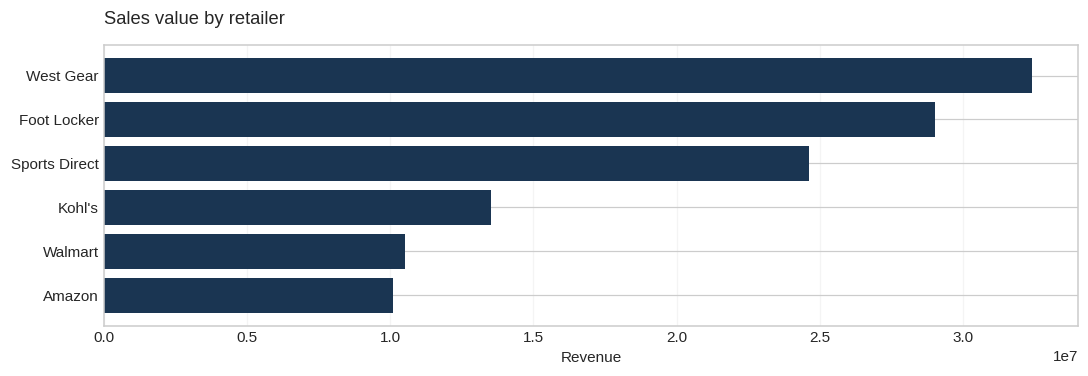

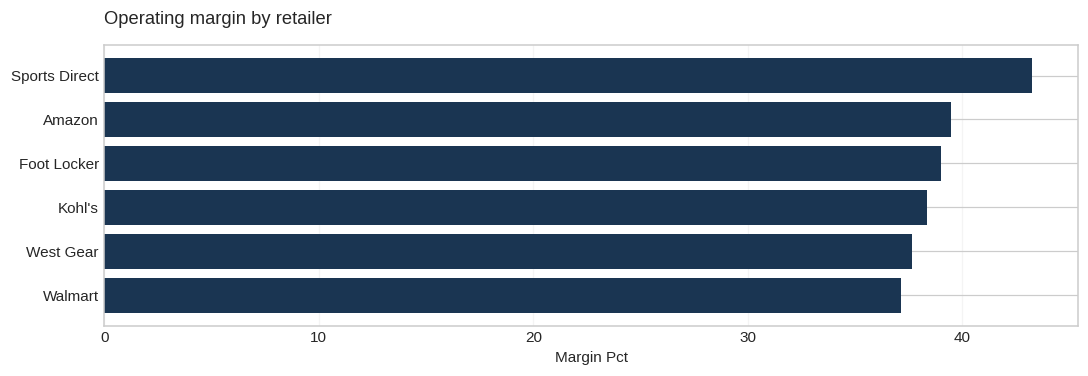

,retailer,units,revenue,profit,margin_pct
5,West Gear,625262,32409558.0,12196890.68,37.63
1,Foot Locker,604369,29024945.0,11317027.31,38.99
3,Sports Direct,557640,24616622.0,10641608.71,43.23
2,Kohl's,287375,13512453.0,5182260.08,38.35
4,Walmart,206225,10506085.0,3902748.86,37.15
0,Amazon,197990,10096987.0,3984432.06,39.46


In [17]:
r=group_metrics(['retailer']).sort_values('revenue',ascending=False)
a=r.iloc[0]; b=r.sort_values('margin_pct',ascending=False).iloc[0]
finding(f"{a.retailer} leads recomputed revenue (${a.revenue/1e6:.2f}M). {b.retailer} leads weighted margin ({b.margin_pct:.2f}%).")
chart(r,'retailer','revenue','Sales value by retailer')
chart(r,'retailer','margin_pct','Operating margin by retailer')
display(r[['retailer','units','revenue','profit','margin_pct']].round(2))

## 5. Time and coverage

Avoid false growth interpretation when 2020 and 2021 geographic coverage differ.

**Observed result.** Observed revenue is $24.24M in 2020 versus $95.93M in 2021; coverage changes from 9 to 46 states.

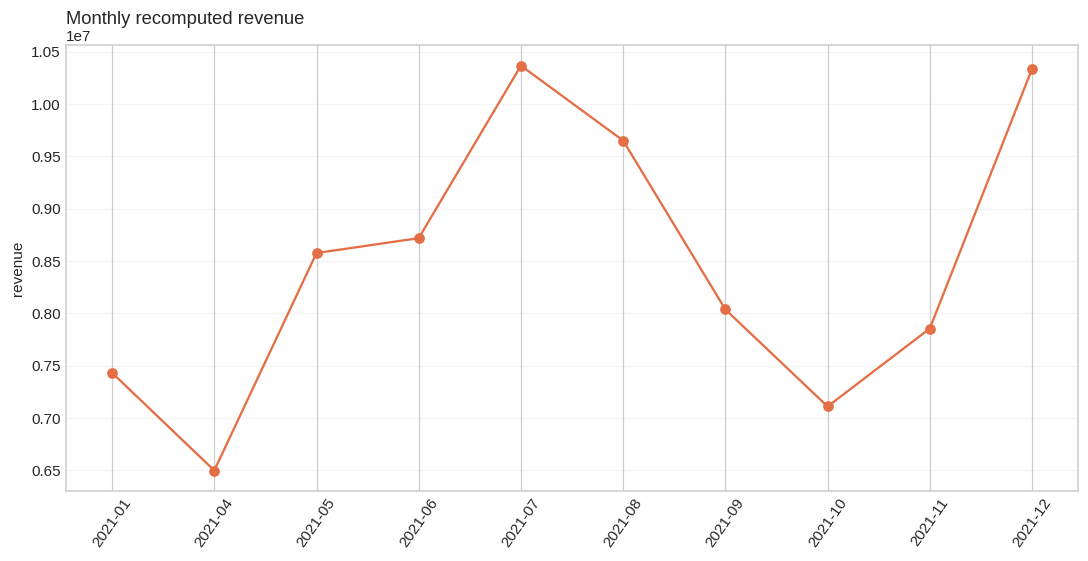

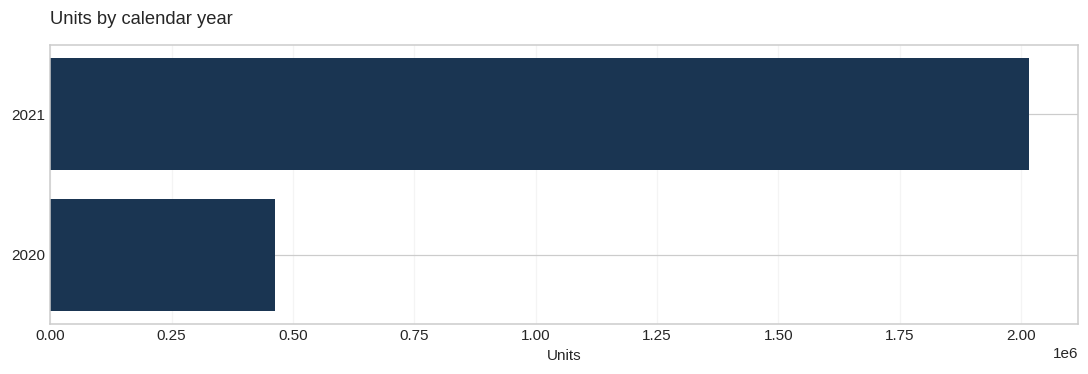

**Interpretation limit.** Year-on-year totals are not a like-for-like commercial growth estimate; observation footprint changes.

,year,units,revenue,profit,margin_pct
0,2020,462349,24237325.0,9015505.08,37.2
1,2021,2016512,95929325.0,38209462.62,39.83


In [18]:
y=group_metrics(['year']).sort_values('year'); t=group_metrics(['year_month']).sort_values('year_month')
states_by_year=df.groupby('year').state.nunique(); a,b=y.iloc[0],y.iloc[1]
finding(f"Observed revenue is ${a.revenue/1e6:.2f}M in {int(a.year)} versus ${b.revenue/1e6:.2f}M in {int(b.year)}; coverage changes from {states_by_year.loc[int(a.year)]} to {states_by_year.loc[int(b.year)]} states.")
chart(t,'year_month','revenue','Monthly recomputed revenue',mode='line')
chart(y.assign(year=y.year.astype(str)),'year','units','Units by calendar year')
caveat('Year-on-year totals are not a like-for-like commercial growth estimate; observation footprint changes.')
display(y[['year','units','revenue','profit','margin_pct']].round(2))

## 6. Geographic performance

Identify sales concentration by region and separate topline from profitability.

**Observed result.** West leads modeled regional revenue ($36.44M), while South has the highest observed regional margin (44.76%).

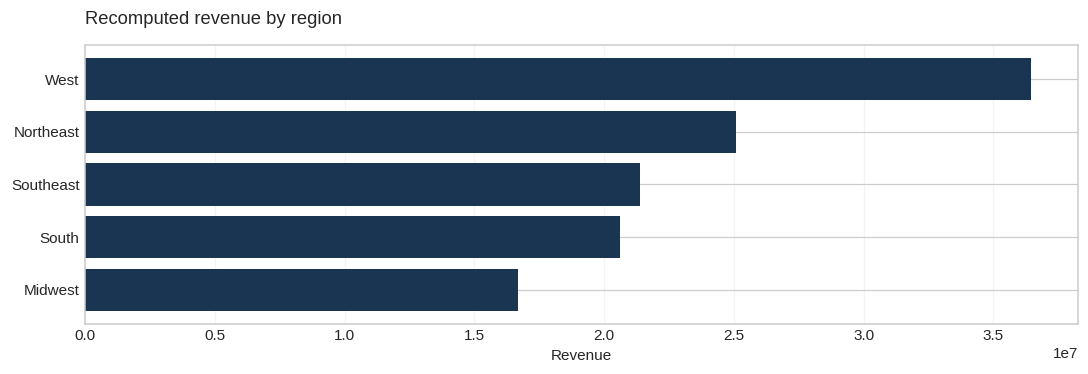

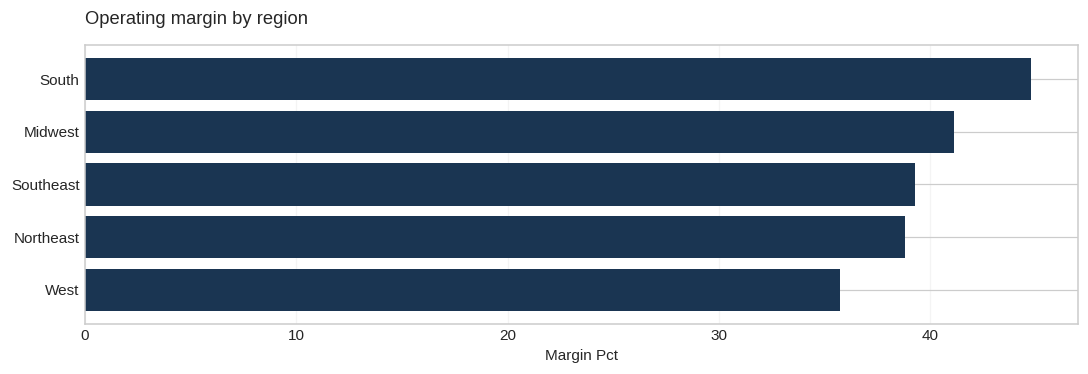

,region,units,revenue,profit,margin_pct
4,West,686985,36436157.0,13017584.05,35.73
1,Northeast,501279,25078267.0,9732773.9,38.81
3,Southeast,407000,21374436.0,8393059.2,39.27
2,South,492260,20603356.0,9221605.32,44.76
0,Midwest,391337,16674434.0,6859945.23,41.14


In [19]:
r=group_metrics(['region']).sort_values('revenue',ascending=False);a=r.iloc[0];b=r.sort_values('margin_pct',ascending=False).iloc[0]
finding(f"{a.region} leads modeled regional revenue (${a.revenue/1e6:.2f}M), while {b.region} has the highest observed regional margin ({b.margin_pct:.2f}%).")
chart(r,'region','revenue','Recomputed revenue by region')
chart(r,'region','margin_pct','Operating margin by region')
display(r[['region','units','revenue','profit','margin_pct']].round(2))

## 7. Product and category mix

Product revenue leadership does not prove customer preference or independent demand.

**Observed result.** Men's Street Footwear has the largest product revenue ($27.68M). Footwear contributes 70.13% of all units.

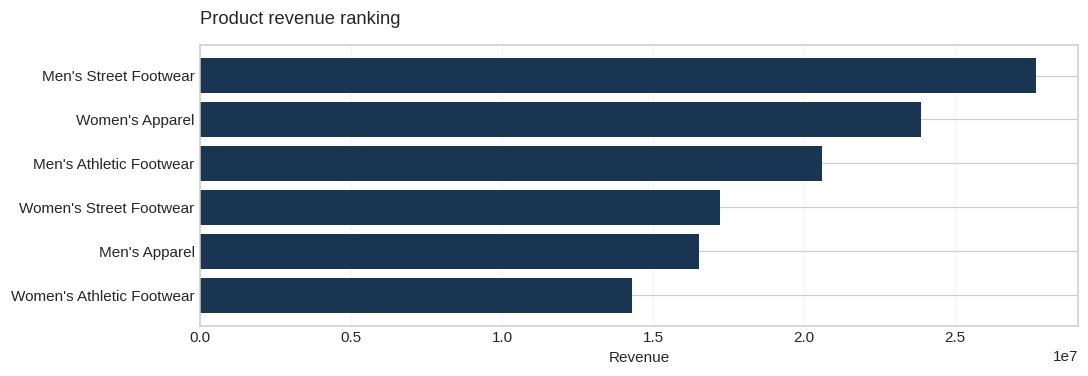

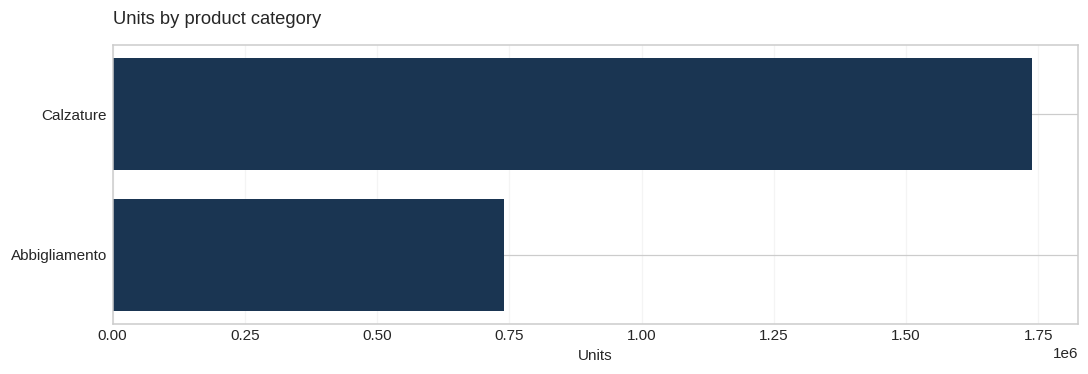

,product,units,revenue,profit,margin_pct
2,Men's Street Footwear,593320,27680769.0,11629045.62,42.01
3,Women's Apparel,433827,23870985.0,9685220.56,40.57
1,Men's Athletic Footwear,435526,20577180.0,7437456.94,36.14
5,Women's Street Footwear,392269,17201563.0,6494016.81,37.75
0,Men's Apparel,306683,16520632.0,6381405.33,38.63
4,Women's Athletic Footwear,317236,14315521.0,5597822.44,39.1


In [20]:
p=group_metrics(['product']).sort_values('revenue',ascending=False);c=group_metrics(['product_category']);a=p.iloc[0]
finding(f"{a['product']} has the largest product revenue (${a.revenue/1e6:.2f}M). Footwear contributes {100*c.loc[c.product_category.eq('Calzature'),'units'].iloc[0]/total_units:.2f}% of all units.")
chart(p,'product','revenue','Product revenue ranking')
chart(c,'product_category','units','Units by product category')
display(p[['product','units','revenue','profit','margin_pct']].round(2))

## 8. Sales methods

Compare channels using revenue-weighted margin and within-retailer mix.

**Observed result.** Online has the highest observed revenue ($44.97M). Online has the highest modeled margin (43.48%).

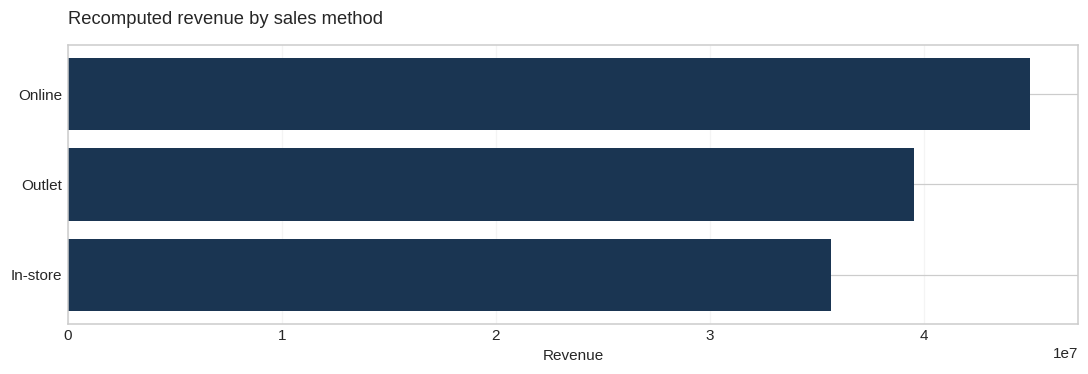

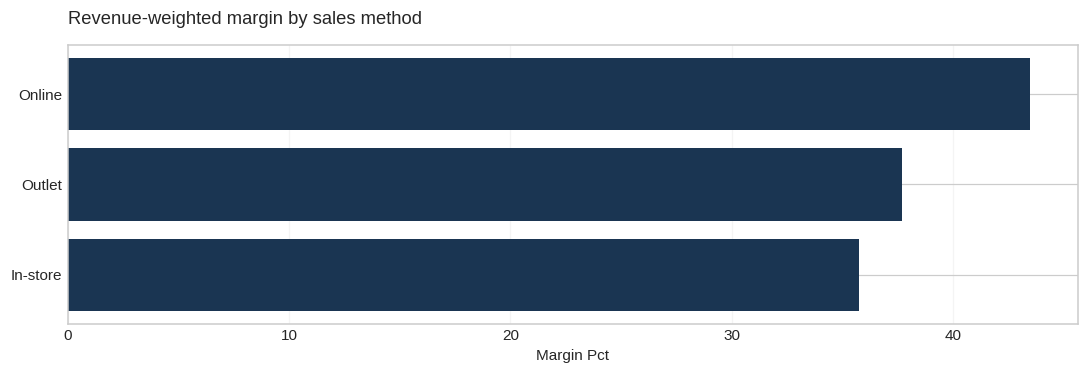

Unit share %,In-store,Online,Outlet
retailer,,,
Amazon,20.23,49.43,30.35
Foot Locker,26.60,42.71,30.69
Kohl's,22.05,39.22,38.72
Sports Direct,19.97,38.90,41.13
Walmart,10.04,33.27,56.69
West Gear,46.98,29.56,23.46


In [21]:
m=group_metrics(['sales_method']).sort_values('revenue',ascending=False);a=m.iloc[0];b=m.sort_values('margin_pct',ascending=False).iloc[0]
finding(f"{a.sales_method} has the highest observed revenue (${a.revenue/1e6:.2f}M). {b.sales_method} has the highest modeled margin ({b.margin_pct:.2f}%).")
chart(m,'sales_method','revenue','Recomputed revenue by sales method')
chart(m,'sales_method','margin_pct','Revenue-weighted margin by sales method')
r=df.pivot_table(index='retailer',columns='sales_method',values='units_sold',aggfunc='sum',fill_value=0);display((r.div(r.sum(axis=1),axis=0)*100).round(2).rename_axis(columns='Unit share %'))

## 9. US holiday windows

Explore holiday windows descriptively: ±3 calendar days vs nearby ±14/21-day reference windows.

**Observed result.** The figures below describe differences in units per observed transaction day; holiday windows overlap and are not causal estimates.

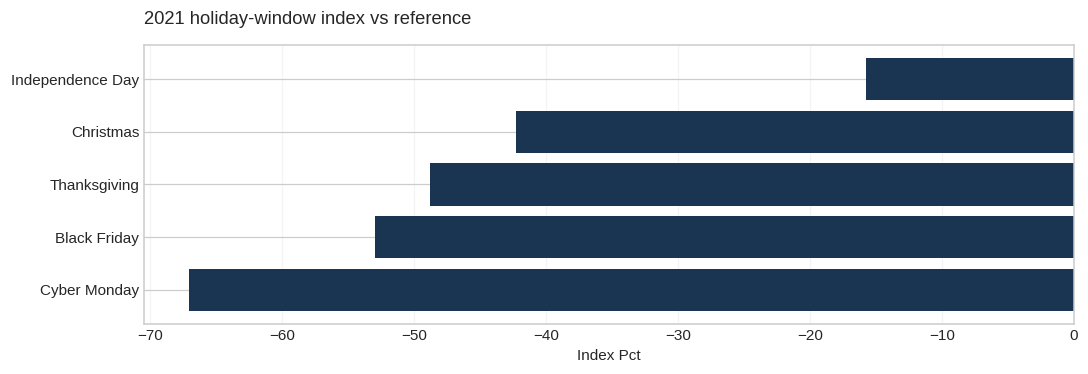

,year,event,window_days,baseline_days,window_states,reference_states,window_units_day,reference_units_day,index_pct
0,2020,Independence Day,7,28,1,3,832.00,995.86,-16.45
1,2020,Thanksgiving,7,28,1,3,381.29,768.93,-50.41
2,2020,Black Friday,7,28,1,3,369.57,745.71,-50.44
3,2020,Cyber Monday,7,25,1,2,377.43,663.04,-43.08
4,2020,Christmas,7,11,2,1,1461.00,244.55,497.43
5,2021,Independence Day,7,28,10,30,5644.43,6701.29,-15.77
6,2021,Thanksgiving,7,28,6,32,3360.00,6562.89,-48.80
7,2021,Black Friday,7,28,5,34,3066.29,6514.50,-52.93
8,2021,Cyber Monday,7,26,4,32,2348.71,7131.42,-67.07
9,2021,Christmas,7,12,6,20,3828.43,6628.83,-42.25


**Interpretation limit.** Neither overlapping-event effects nor promotions can be isolated. Some baseline windows have different states and observation days.

In [22]:
holiday_dates={2020:{'Independence Day':'2020-07-04','Thanksgiving':'2020-11-26','Black Friday':'2020-11-27','Cyber Monday':'2020-11-30','Christmas':'2020-12-25'},2021:{'Independence Day':'2021-07-04','Thanksgiving':'2021-11-25','Black Friday':'2021-11-26','Cyber Monday':'2021-11-29','Christmas':'2021-12-25'}}
all_holiday_days=set()
for year,mp in holiday_dates.items():
    for label,date in mp.items():
        t=pd.Timestamp(date);all_holiday_days.update(pd.date_range(t-pd.Timedelta(days=3),t+pd.Timedelta(days=3)))
rows=[]
for year,mp in holiday_dates.items():
    for label,date in mp.items():
        t=pd.Timestamp(date);w=df[df.invoice_date.between(t-pd.Timedelta(days=3),t+pd.Timedelta(days=3))]
        candidates=[]
        for lag in (-21,-14,14,21):
            c=t+pd.Timedelta(days=lag)
            candidates.extend(z for z in pd.date_range(c-pd.Timedelta(days=3),c+pd.Timedelta(days=3)) if z not in all_holiday_days and z.year==year)
        ref=df[df.invoice_date.isin(candidates)]; nw=w.invoice_date.nunique(); nr=ref.invoice_date.nunique()
        wd=w.units_sold.sum()/nw if nw else np.nan;rd=ref.units_sold.sum()/nr if nr else np.nan
        rows.append({'year':year,'event':label,'window_days':nw,'baseline_days':nr,'window_states':w.state.nunique(),'reference_states':ref.state.nunique(),'window_units_day':wd,'reference_units_day':rd,'index_pct':(wd/rd-1)*100 if rd else np.nan})
h=pd.DataFrame(rows);x=h[h.year.eq(2021)].copy()
finding('The figures below describe differences in units per observed transaction day; holiday windows overlap and are not causal estimates.')
chart(x,'event','index_pct','2021 holiday-window index vs reference')
display(h.round(2))
caveat('Neither overlapping-event effects nor promotions can be isolated. Some baseline windows have different states and observation days.')

## 10. Profitability and commercial trade-offs

Evaluate revenue scale and modeled operating margin jointly; explore concentration without treating correlations as causal.

**Observed result.** The top two retailers account for 51.12% of recomputed revenue. Overall weighted margin is 39.30%.

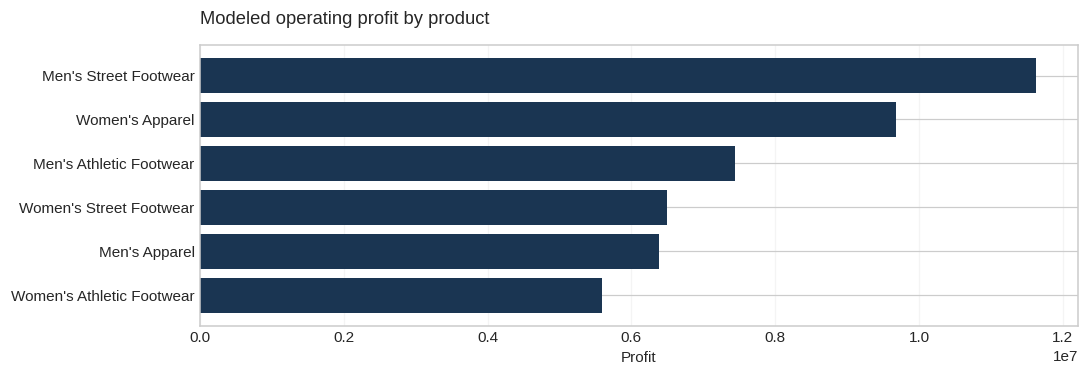

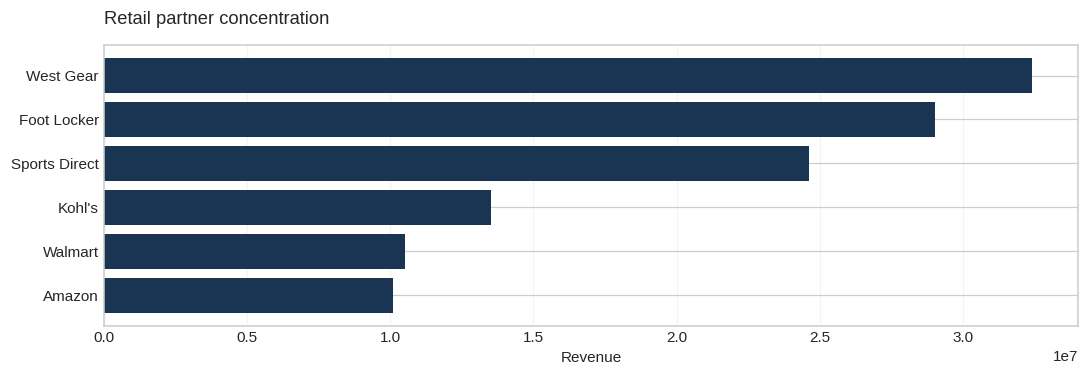

,retailer,revenue,profit,margin_pct,realized_unit_price
5,West Gear,32409558.0,12196890.68,37.63,51.83
1,Foot Locker,29024945.0,11317027.31,38.99,48.03
3,Sports Direct,24616622.0,10641608.71,43.23,44.14
2,Kohl's,13512453.0,5182260.08,38.35,47.02
4,Walmart,10506085.0,3902748.86,37.15,50.94
0,Amazon,10096987.0,3984432.06,39.46,51.0


**Interpretation limit.** Modeled profit uses source-provided margin; without independent cost data it cannot be validated as audited operating profit.

In [23]:
r=group_metrics(['retailer']).sort_values('revenue',ascending=False);p=group_metrics(['product']).sort_values('profit',ascending=False)
share=100*r.revenue.head(2).sum()/total_revenue; margin=100*total_profit/total_revenue
finding(f"The top two retailers account for {share:.2f}% of recomputed revenue. Overall weighted margin is {margin:.2f}%.")
chart(p,'product','profit','Modeled operating profit by product')
chart(r,'retailer','revenue','Retail partner concentration')
display(r[['retailer','revenue','profit','margin_pct','realized_unit_price']].round(2))
caveat('Modeled profit uses source-provided margin; without independent cost data it cannot be validated as audited operating profit.')

## Conclusions and recommendations

**Observed:** West Gear leads retailer revenue, the West leads regional revenue, Men's Street Footwear leads product revenue, and Online leads modeled sales-method profitability. 2021 covers far more states than 2020. Revenue is materially sensitive to the chosen normalization rule.

**Interpretation:** Revenue scale and weighted profitability are distinct business objectives. Aggregate time comparisons are biased by a shifting observed footprint. Neither product mix nor holiday windows identify consumer-level preferences or a causal sales lift.

**Recommendations to investigate:** (1) reconcile the 3,886 source-scale anomalies before any financial decision; (2) build like-for-like retailer/state/date cohorts before discussing growth; (3) examine controlled pilots around Online economics, profitable regions and product assortments with actual cost, inventory and customer data. None is a proven causal intervention from this dataset alone.

**Limits:** No unique order/customer IDs, no verified return or discount fields, no cost detail, no independent margin verification, changing coverage, overlapping holiday periods, third-party dataset provenance. This notebook is a portfolio case study, not an official Adidas statement.